In [1]:
from pathlib import Path

import cartopy.crs as ccrs
from cartopy.feature import LAND
import matplotlib.dates as mdates
from matplotlib.cm import ScalarMappable
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd

POINTS_PATH = Path("../data/points.feather")

CENTER_X_M = 700_000
CENTER_Y_M = -800_000
BUFFER_M = 200_000
TIME_START = "2020-02-20"
TIME_END = "2020-02-25"

PLOT_PAD_M = 75_000
MIN_PLOT_SEGMENT_LENGTH_M = 1_000


## Select trajectories passing through a space-time window

Change the centre point, buffer, and dates in the first cell. The selection returns the full trajectories for every trajectory with at least one point inside the box during the date range.


In [2]:
df = (
    pd.read_feather(POINTS_PATH)
    .assign(d=lambda x: pd.to_datetime(x.d))
    .sort_values(["g", "d"])
    .reset_index(drop=True)
)

df.head()


In [3]:
def bounds_from_center(center_x_m, center_y_m, buffer_m):
    return (center_x_m - buffer_m, center_x_m + buffer_m), (center_y_m - buffer_m, center_y_m + buffer_m)


def select_trajectories_passing_through(points, time_start, time_end, xlim, ylim):
    in_domain = (
        points.d.between(pd.Timestamp(time_start), pd.Timestamp(time_end))
        & points.x.between(xlim[0], xlim[1])
        & points.y.between(ylim[0], ylim[1])
    )
    domain_points = points.loc[in_domain].copy()
    trajectory_ids = np.sort(domain_points.g.unique())
    selected = points.loc[points.g.isin(trajectory_ids)].copy()
    return selected, domain_points, trajectory_ids


## Run the selection


In [4]:
xlim, ylim = bounds_from_center(CENTER_X_M, CENTER_Y_M, BUFFER_M)
selected_trajectories, domain_points, trajectory_ids = select_trajectories_passing_through(
    df,
    TIME_START,
    TIME_END,
    xlim,
    ylim,
)

summary = pd.Series({
    "time_start": pd.Timestamp(TIME_START),
    "time_end": pd.Timestamp(TIME_END),
    "center_x_m": CENTER_X_M,
    "center_y_m": CENTER_Y_M,
    "buffer_m": BUFFER_M,
    "x_min_m": xlim[0],
    "x_max_m": xlim[1],
    "y_min_m": ylim[0],
    "y_max_m": ylim[1],
    "domain_points": len(domain_points),
    "selected_trajectories": len(trajectory_ids),
    "selected_trajectory_points": len(selected_trajectories),
})
summary


In [5]:
trajectory_summary = selected_trajectories.groupby("g").agg(
    first_time=("d", "min"),
    last_time=("d", "max"),
    n_points=("d", "size"),
    domain_points=("g", lambda values: int(values.index.isin(domain_points.index).sum())),
)
trajectory_summary["duration_days"] = (
    trajectory_summary.last_time - trajectory_summary.first_time
).dt.total_seconds() / 86_400
trajectory_summary.sort_values(["domain_points", "n_points"], ascending=False).head(10)


## Plot the query


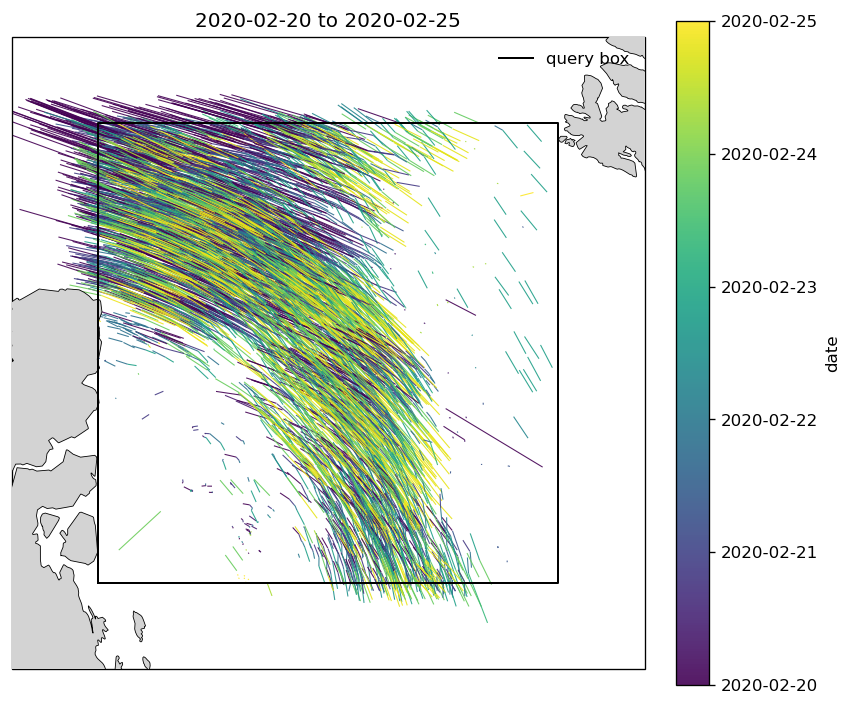

In [6]:
def point_in_query(points, time_start, time_end, xlim, ylim, *, x_col="x", y_col="y", time_col="d"):
    return (
        points[time_col].between(pd.Timestamp(time_start), pd.Timestamp(time_end))
        & points[x_col].between(xlim[0], xlim[1])
        & points[y_col].between(ylim[0], ylim[1])
    )


def trajectory_segments_touching_query(points, time_start, time_end, xlim, ylim):
    frame = points.sort_values(["g", "d"]).copy()
    frame[["x2", "y2", "d2"]] = frame.groupby("g")[["x", "y", "d"]].shift(-1)
    frame = frame.dropna(subset=["x2", "y2", "d2"]).copy()
    frame = frame[(frame.d2 - frame.d).dt.total_seconds() > 0].copy()

    start_in = point_in_query(frame, time_start, time_end, xlim, ylim)
    end_in = point_in_query(frame, time_start, time_end, xlim, ylim, x_col="x2", y_col="y2", time_col="d2")
    frame = frame.loc[start_in | end_in].copy()
    frame["segment_time"] = frame.d + (frame.d2 - frame.d) / 2
    frame["segment_length_m"] = np.hypot(frame.x2 - frame.x, frame.y2 - frame.y)
    return frame


projection = ccrs.NorthPolarStereo(central_longitude=-45, true_scale_latitude=70.0)
plot_segments = trajectory_segments_touching_query(
    selected_trajectories,
    TIME_START,
    TIME_END,
    xlim,
    ylim,
)
plot_segments = plot_segments.loc[plot_segments.segment_length_m >= MIN_PLOT_SEGMENT_LENGTH_M].copy()

time_norm = Normalize(mdates.date2num(pd.Timestamp(TIME_START)), mdates.date2num(pd.Timestamp(TIME_END)))
cmap = "viridis"

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": projection}, constrained_layout=True)
ax.add_feature(LAND, zorder=3, edgecolor="black", facecolor="lightgray", linewidth=0.5)

if not plot_segments.empty:
    xy = plot_segments[["x", "y", "x2", "y2"]].to_numpy(dtype=float).reshape(-1, 2, 2)
    lines = LineCollection(xy, cmap=cmap, norm=time_norm, linewidths=0.65, alpha=0.9, capstyle="butt", transform=projection, zorder=2)
    lines.set_array(mdates.date2num(plot_segments.segment_time))
    ax.add_collection(lines)
    color_source = lines
else:
    color_source = ScalarMappable(norm=time_norm, cmap=cmap)
    color_source.set_array([])

box_x = [xlim[0], xlim[1], xlim[1], xlim[0], xlim[0]]
box_y = [ylim[0], ylim[0], ylim[1], ylim[1], ylim[0]]
ax.plot(box_x, box_y, color="black", linewidth=1.2, transform=projection, zorder=4, label="query box")

ax.set_extent(
    [xlim[0] - PLOT_PAD_M, xlim[1] + PLOT_PAD_M, ylim[0] - PLOT_PAD_M, ylim[1] + PLOT_PAD_M],
    crs=projection,
)
ax.set_xlabel("x EPSG:3413 (m)")
ax.set_ylabel("y EPSG:3413 (m)")
ax.set_title(
    f"{pd.Timestamp(TIME_START):%Y-%m-%d} to {pd.Timestamp(TIME_END):%Y-%m-%d}"
)
ax.legend(frameon=False, loc="upper right")

cbar = fig.colorbar(color_source, ax=ax, shrink=0.8, label="date")
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

plt.show()
